In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent / 'python'))
from analysis_common import analytical_src, segment_metrics
from config import AGGREGATE_DIR, AUDIT_DIR, CLEAN_PARQUET, DOCS_DIR, STATS_DIR, VISUALS_DIR, connect
pd.set_option('display.max_columns', 40, 'display.width', 180, 'display.float_format', '{:,.4f}'.format)
con = connect(); src = analytical_src()
kpi = json.loads((AGGREGATE_DIR / 'portfolio_kpis.json').read_text())
fin = json.loads((AGGREGATE_DIR / 'financial_totals.json').read_text())
show = lambda name: display(Image(filename=str(VISUALS_DIR / f'{name}.png')))
csv = lambda name: pd.read_csv(AGGREGATE_DIR / f'{name}.csv')

# 4. Borrower Risk Analysis
Associations from `python/borrower_analysis.py`. Grade already prices much of this risk.

In [2]:
csv('borrower_profile').T

,0
avg_income,"78,049.9823"
median_income,"65,000.0000"
avg_dti,18.7656
median_dti,17.8400
avg_emp_years,5.9314
avg_fico,700.5883
avg_history_years,16.3947


In [3]:
csv('borrower_profile_by_outcome')

,status_clean,loans,median_income,avg_dti,avg_fico,avg_rate,avg_funded
0,Charged Off,268559,"60,000.0000",20.1384,689.8501,15.7107,"15,557.0598"
1,Fully Paid,1076751,"65,000.0000",17.7852,700.2640,12.6233,"14,125.8497"


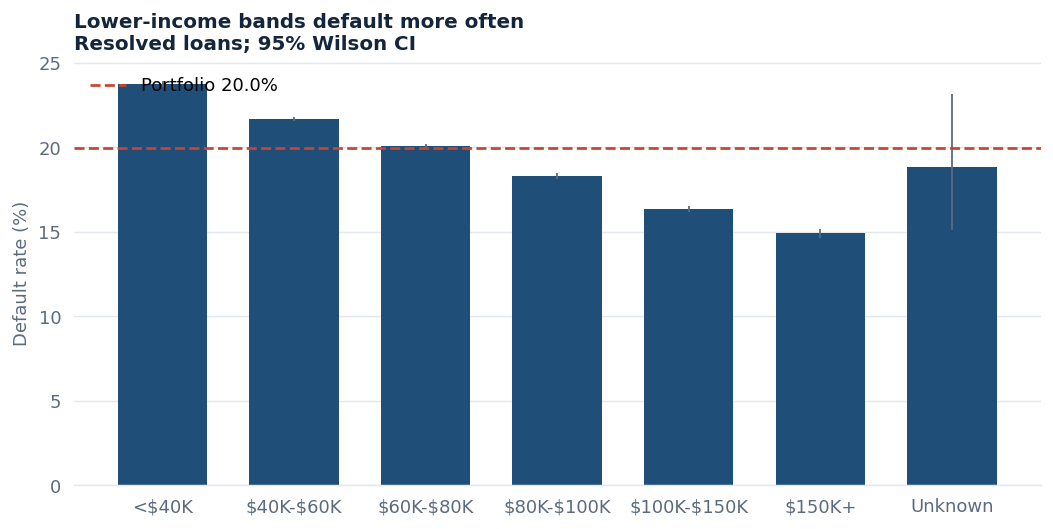

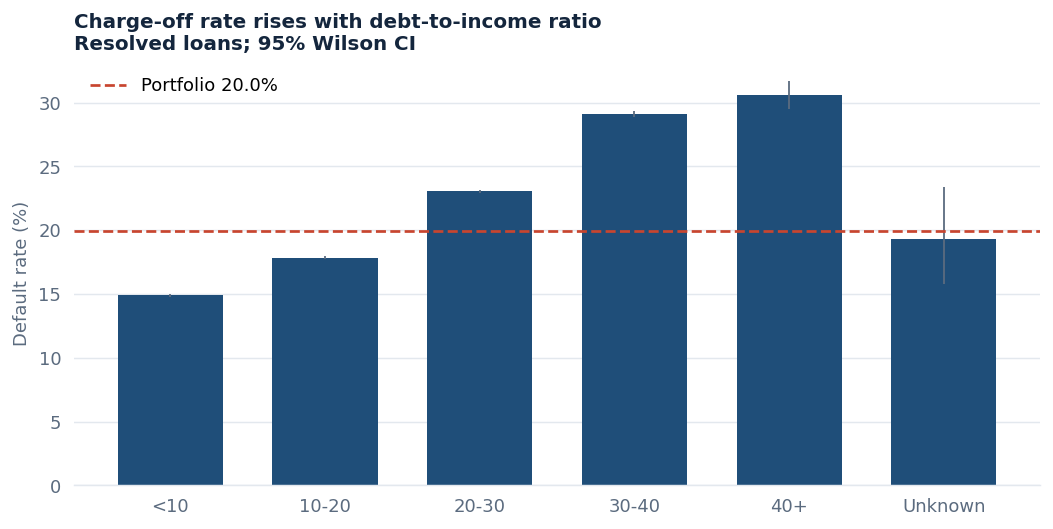

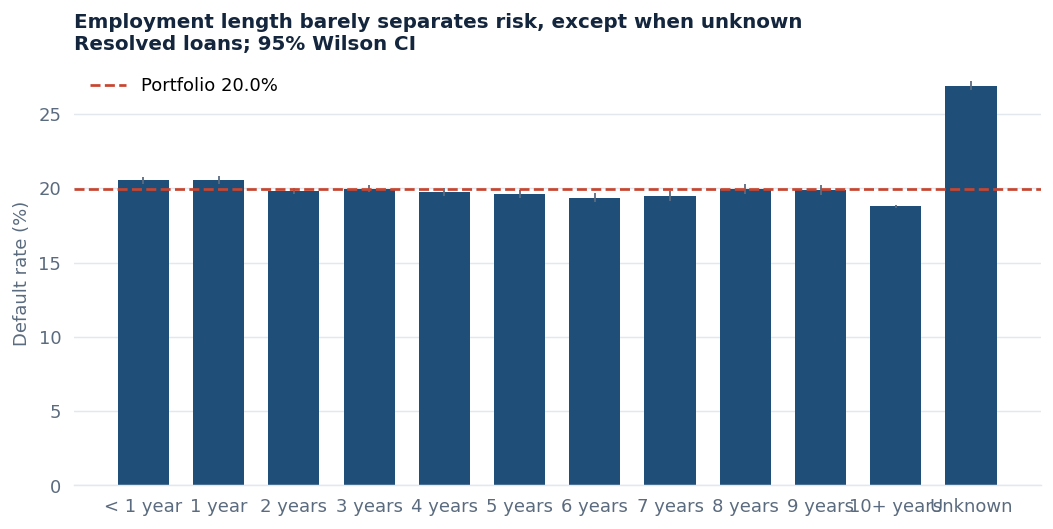

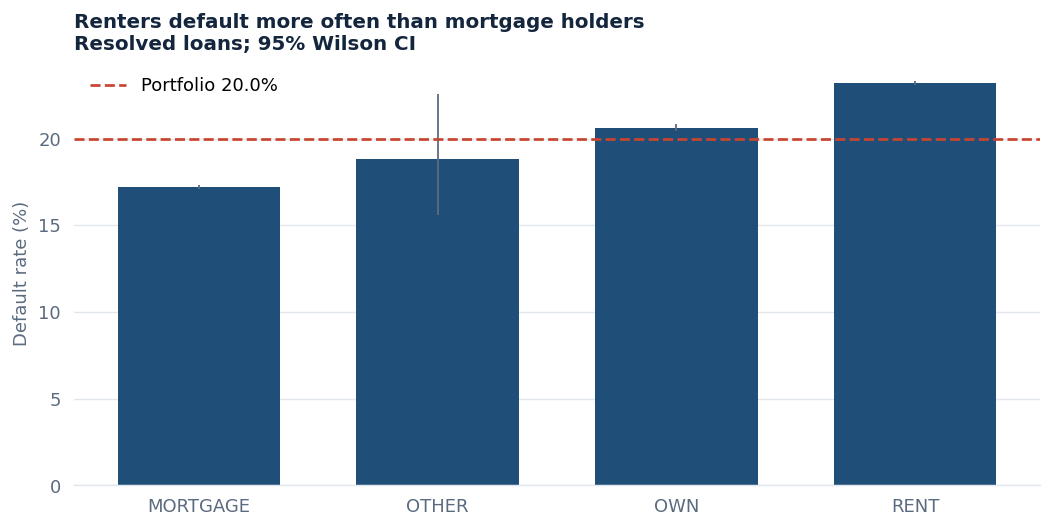

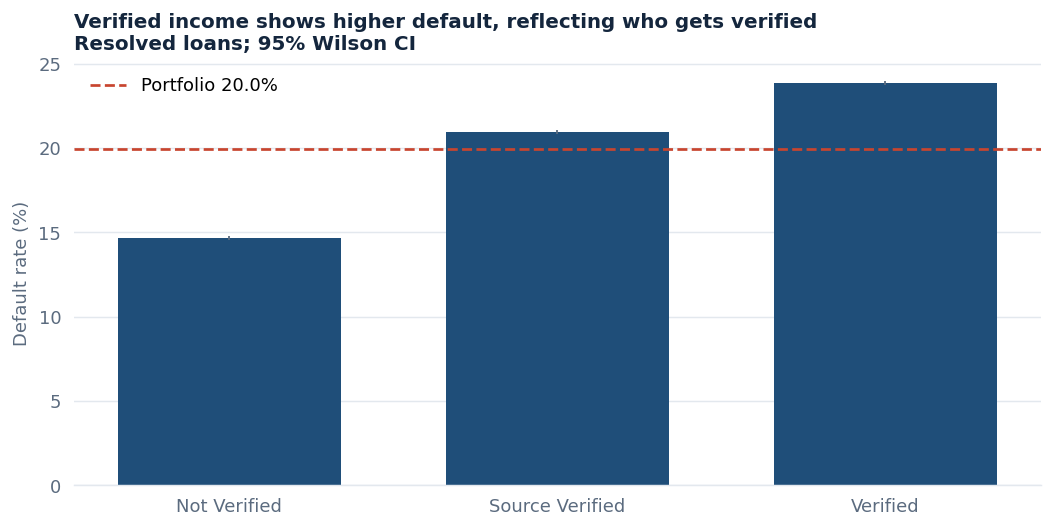

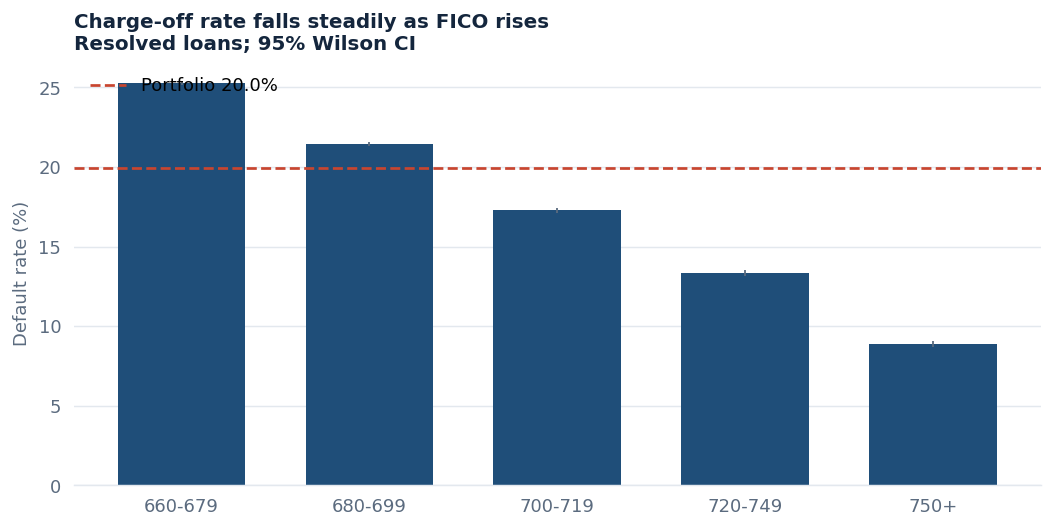

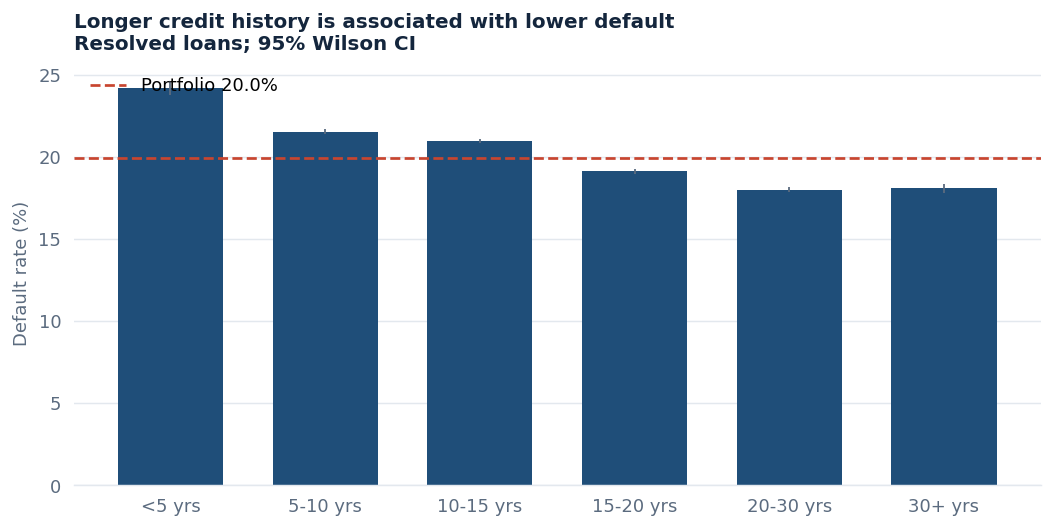

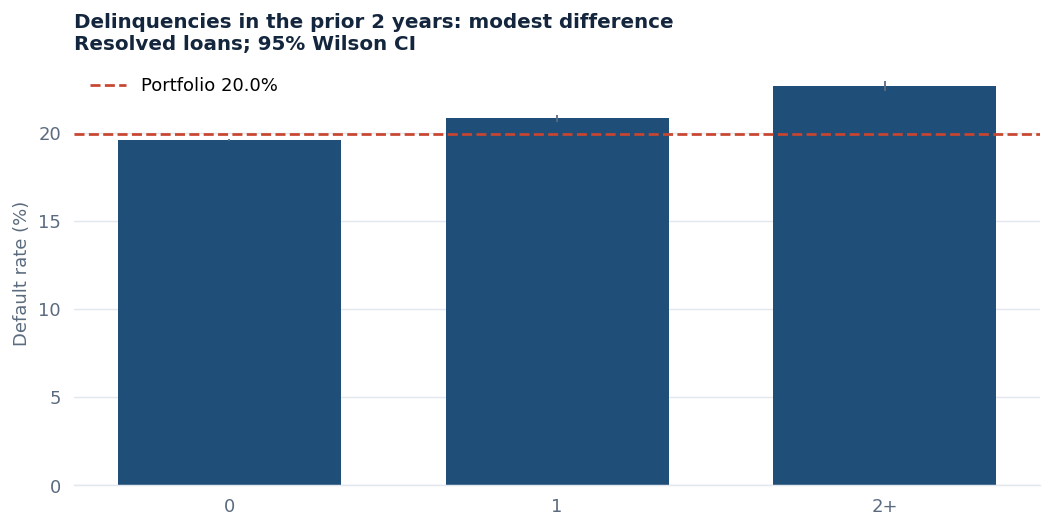

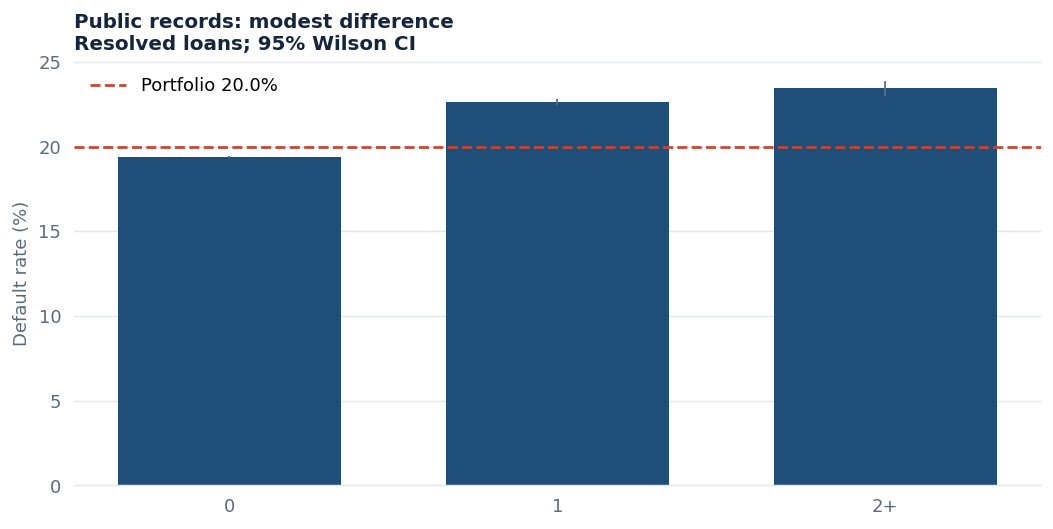

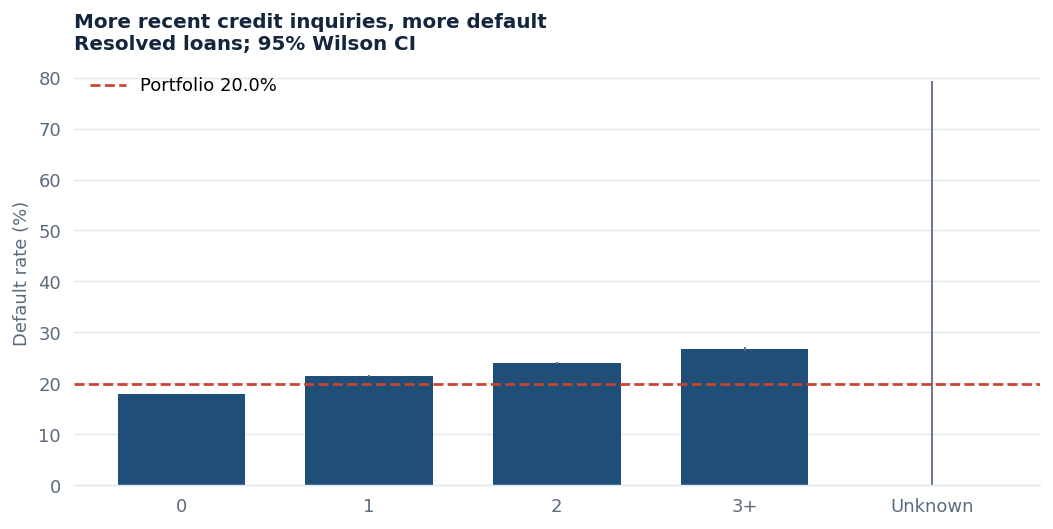

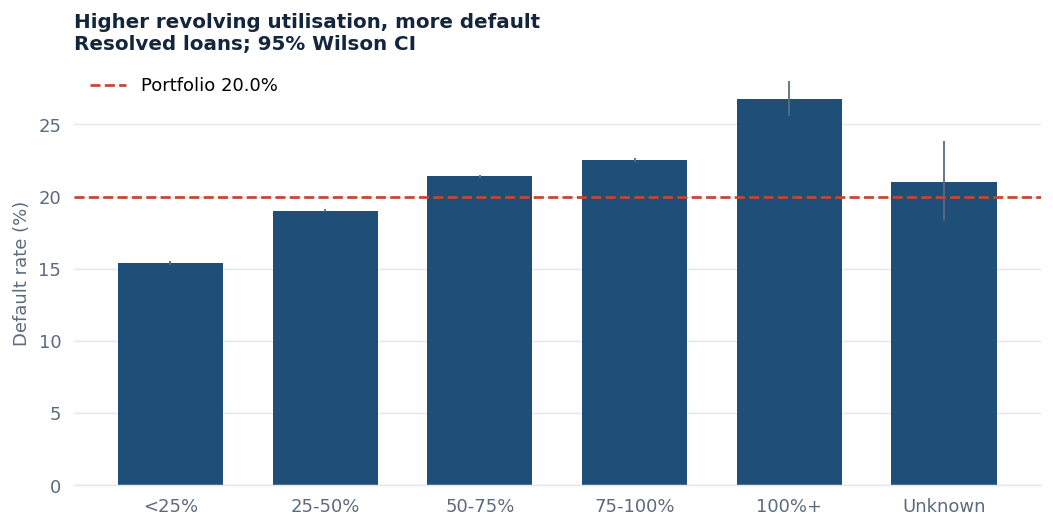

In [4]:
for n in ['income_band','dti_band','emp_length_label','home_ownership_group','verification_status','fico_band','credit_history_band','delinq_band','pub_rec_band','inquiry_band','revol_util_band']:
    show(f'c_default_by_{n}')

Employment length barely separates risk among stated values, while missing employment length stands out. Verified loans look riskier, which likely reflects who gets verified.

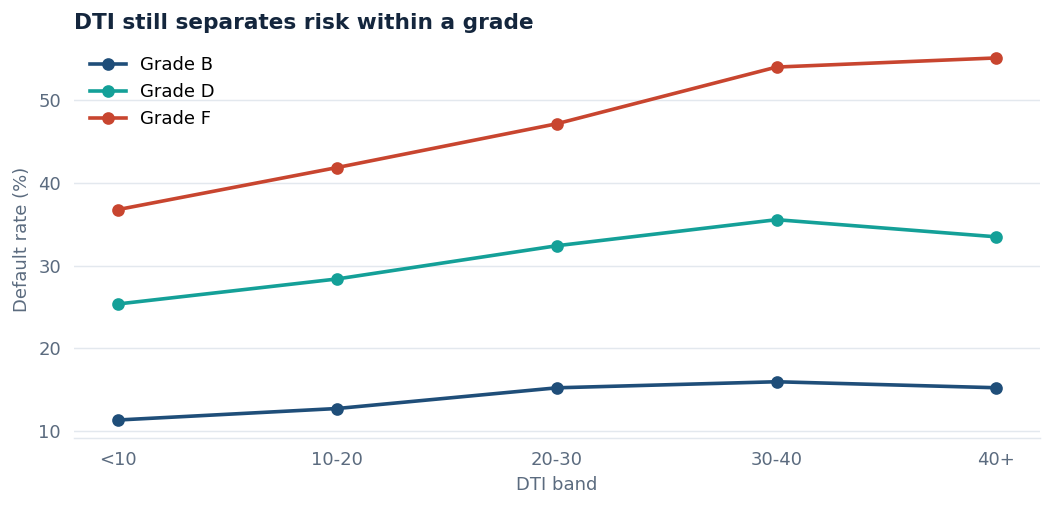

In [5]:
show('c_dti_within_grade')

In [6]:
segment_metrics(con, ['grade','dti_band'], src).pivot(index='grade', columns='dti_band', values='default_rate')[['<10','10-20','20-30','30-40','40+']]

dti_band,<10,10-20,20-30,30-40,40+
grade,,,,,
A,0.0489,0.0568,0.0759,0.0856,0.0939
B,0.1133,0.1272,0.1523,0.1596,0.1523
C,0.1906,0.2102,0.2476,0.2590,0.2708
D,0.2536,0.2840,0.3242,0.3557,0.3349
E,0.3074,0.3575,0.4088,0.4530,0.4384
F,0.3678,0.4188,0.4718,0.5403,0.5514
G,0.4441,0.4626,0.5129,0.5733,0.6218
